# Heart Disease Prediction

**Goal:** predict whether a patient has heart disease from 13 clinical measurements
(age, sex, chest pain type, blood pressure, cholesterol, maximum heart rate, etc.).

**Dataset:** UCI Heart Disease (Cleveland), Kaggle version, 303 patients, saved in `data/heart.csv`.

Notebook outline:
1. Data loading and cleaning
2. Exploratory data analysis (EDA)
3. Feature importance
4. Model training and parameter tuning (Logistic Regression, Decision Tree, Random Forest, XGBoost)
5. Final model evaluation on the test set

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, mutual_info_score, accuracy_score
import xgboost as xgb

%matplotlib inline

## 1. Data loading and cleaning

In [2]:
df = pd.read_csv('data/heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


Column meanings:

| column | meaning |
|---|---|
| age | age in years |
| sex | 1 = male, 0 = female |
| cp | chest pain type (0 to 3) |
| trestbps | resting blood pressure (mm Hg) |
| chol | serum cholesterol (mg/dl) |
| fbs | fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | resting electrocardiographic results (0 to 2) |
| thalach | maximum heart rate achieved |
| exang | exercise induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | slope of the peak exercise ST segment (0 to 2) |
| ca | number of major vessels colored by fluoroscopy (0 to 3) |
| thal | thalassemia test result (1 to 3) |
| target | 1 = heart disease, 0 = no heart disease |

In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicated rows:', df.duplicated().sum())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicated rows: 1


There are no NaN values, but there is one duplicated row, which we remove.

Two columns contain invalid codes:
* `ca` should be 0 to 3, but has the value 4 for some rows
* `thal` should be 1 to 3, but has the value 0 for some rows

These are missing values in the original UCI data. We replace them with the most frequent value of the column.

In [5]:
print(df['ca'].value_counts().sort_index())
print(df['thal'].value_counts().sort_index())

ca
0    175
1     65
2     38
3     20
4      5
Name: count, dtype: int64
thal
0      2
1     18
2    166
3    117
Name: count, dtype: int64


In [6]:
df = df.drop_duplicates().reset_index(drop=True)

df.loc[df['ca'] == 4, 'ca'] = df['ca'].mode()[0]
df.loc[df['thal'] == 0, 'thal'] = df['thal'].mode()[0]

print(df.shape)
print(df['ca'].value_counts().sort_index().to_dict())
print(df['thal'].value_counts().sort_index().to_dict())

(302, 14)
{0: 179, 1: 65, 2: 38, 3: 20}
{1: 18, 2: 167, 3: 117}


Numerical and categorical features. The categorical features are stored as integer codes, so we
convert them to strings: this way `DictVectorizer` will one-hot encode them instead of treating them as numbers.

In [7]:
numerical = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for c in categorical:
    df[c] = df[c].astype(str)

## 2. Exploratory data analysis

### Target variable

target
1    164
0    138
Name: count, dtype: int64

target
1    0.543
0    0.457
Name: proportion, dtype: float64


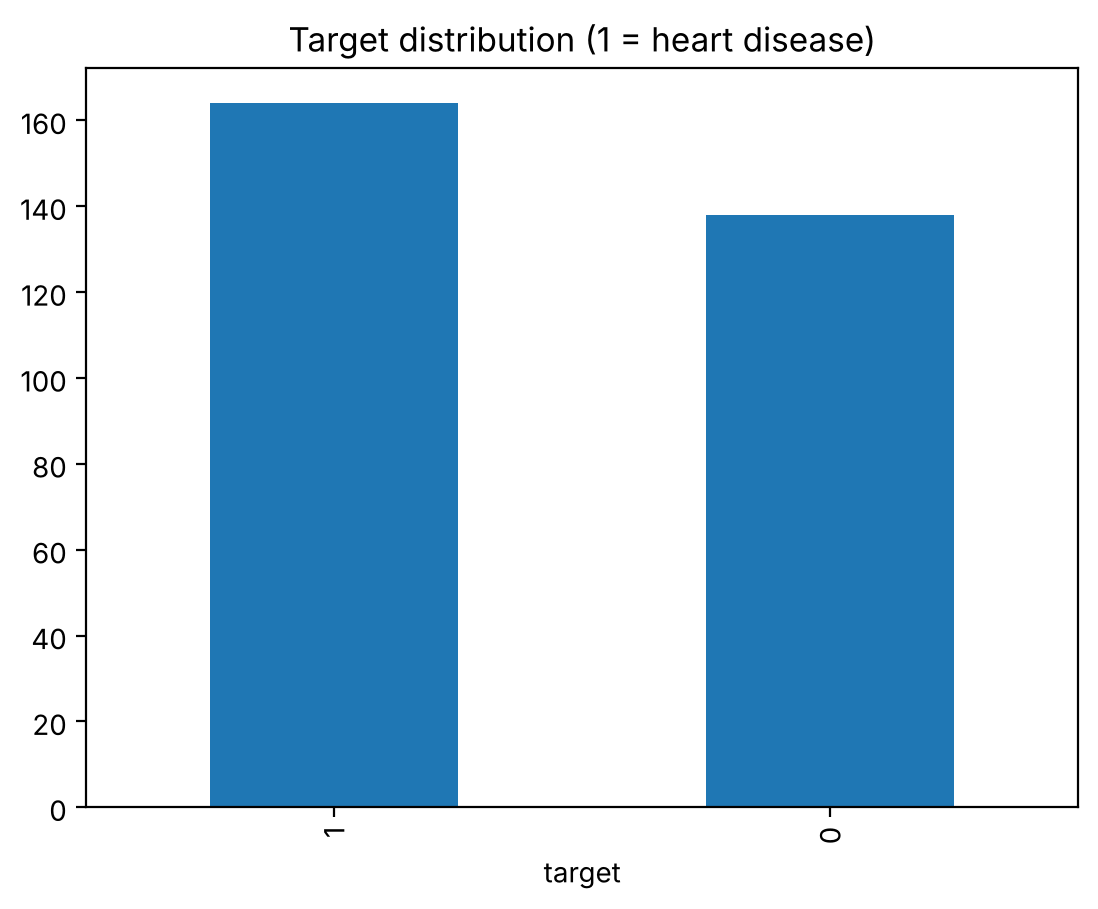

In [8]:
print(df['target'].value_counts())
print()
print(df['target'].value_counts(normalize=True).round(3))

df['target'].value_counts().plot(kind='bar')
plt.title('Target distribution (1 = heart disease)')
plt.show()

The classes are fairly balanced (about 54% / 46%), so ROC AUC and accuracy are both meaningful metrics.

### Numerical features: ranges and distributions

In [9]:
df[numerical].describe().round(2)

,age,trestbps,chol,thalach,oldpeak
count,302.00,302.00,302.00,302.00,302.00
mean,54.42,131.60,246.50,149.57,1.04
std,9.05,17.56,51.75,22.90,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.25,0.00
50%,55.50,130.00,240.50,152.50,0.80
75%,61.00,140.00,274.75,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20


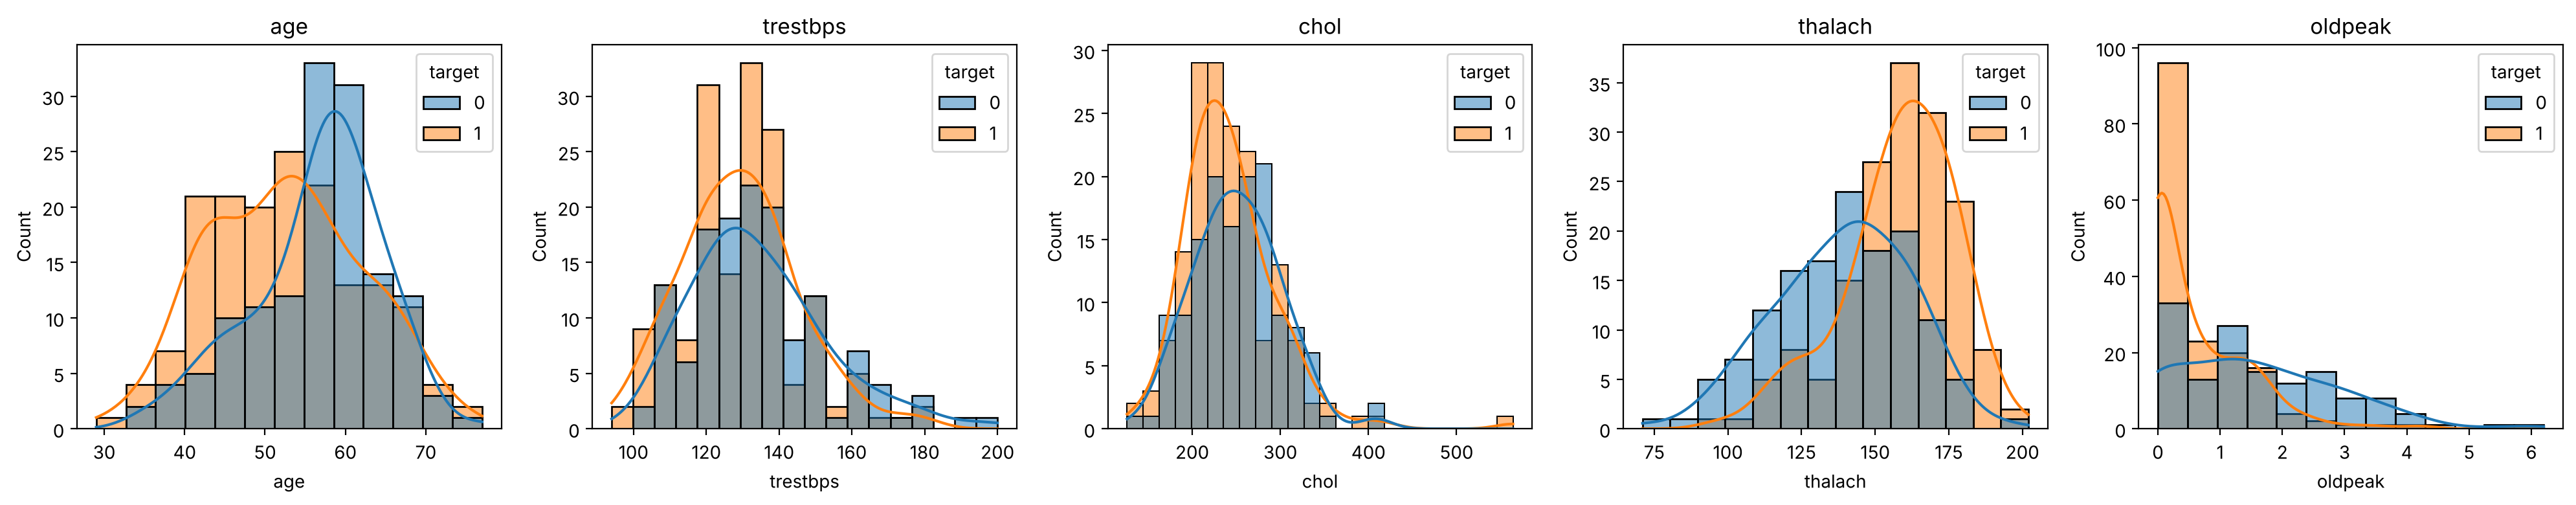

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numerical):
    sns.histplot(data=df, x=col, hue='target', kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

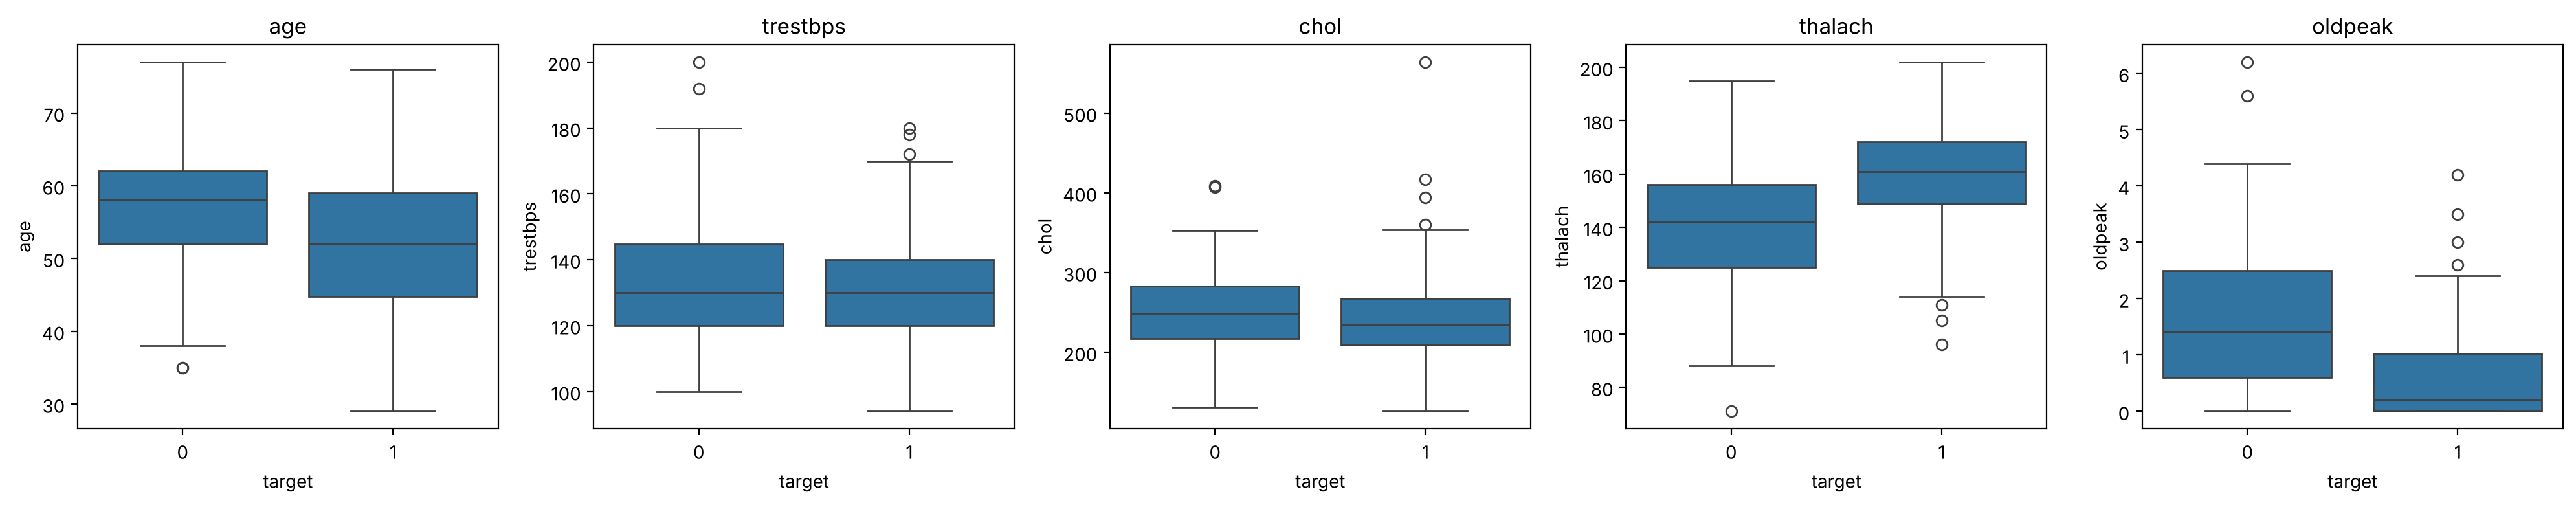

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numerical):
    sns.boxplot(data=df, x='target', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Observations:
* `thalach` (maximum heart rate) is clearly higher for target = 1
* `oldpeak` is clearly lower for target = 1
* `age` is slightly lower for target = 1
* `chol` and `trestbps` differ little between the two groups; `chol` has a few large outliers (above 500)

### Correlation between numerical features

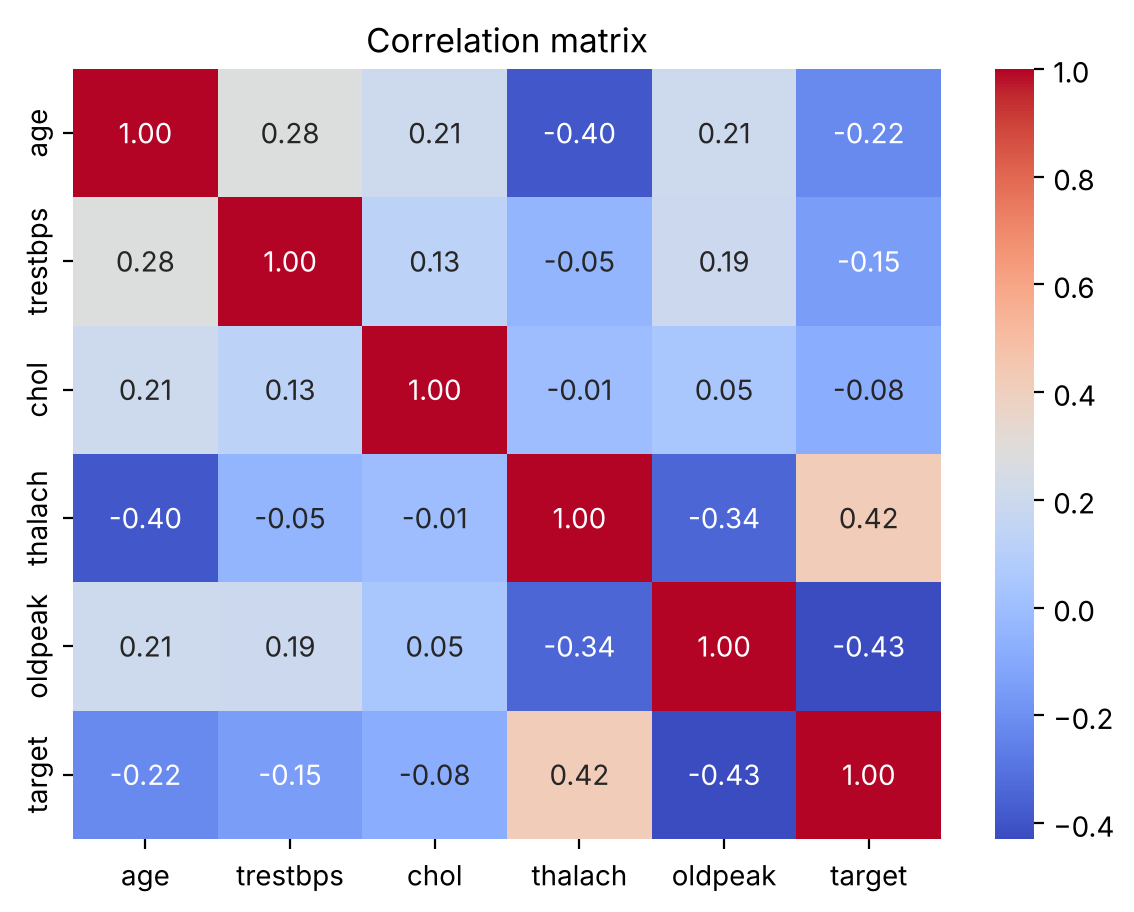

In [12]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[numerical + ['target']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix')
plt.show()

### Categorical features: disease rate per category

In [13]:
global_rate = df['target'].mean()
print('Global heart disease rate:', round(global_rate, 3))

for c in categorical:
    df_group = df.groupby(c)['target'].agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    print()
    print(c)
    print(df_group.round(3))

Global heart disease rate: 0.543

sex
      mean  count   diff   risk
sex                            
0    0.750     96  0.207  1.381
1    0.447    206 -0.096  0.822

cp
     mean  count   diff   risk
cp                            
0   0.273    143 -0.270  0.502
1   0.820     50  0.277  1.510
2   0.791     86  0.248  1.456
3   0.696     23  0.153  1.281

fbs
      mean  count   diff   risk
fbs                            
0    0.549    257  0.006  1.010
1    0.511     45 -0.032  0.941

restecg
          mean  count   diff   risk
restecg                            
0        0.463    147 -0.080  0.852
1        0.629    151  0.086  1.159
2        0.250      4 -0.293  0.460

exang
        mean  count   diff   risk
exang                            
0      0.695    203  0.152  1.279
1      0.232     99 -0.311  0.428

slope
        mean  count   diff   risk
slope                            
0      0.429     21 -0.114  0.789
1      0.350    140 -0.193  0.645
2      0.752    141  0.209  1.384

c

## 3. Feature importance

### Mutual information (categorical features)

In [14]:
mi = df[categorical].apply(lambda col: mutual_info_score(col, df['target']))
mi.sort_values(ascending=False)

thal       0.145851
cp         0.141042
ca         0.128140
exang      0.098085
slope      0.080175
sex        0.041769
restecg    0.016254
fbs        0.000359
dtype: float64

### Correlation with the target (numerical features)

In [15]:
df[numerical].corrwith(df['target']).sort_values()

oldpeak    -0.429146
age        -0.221476
trestbps   -0.146269
chol       -0.081437
thalach     0.419955
dtype: float64

The most informative categorical features are `thal`, `cp`, `ca` and `exang`;
`fbs` carries almost no information. Among numerical features, `oldpeak` and `thalach`
are the most correlated with the target.

## 4. Model training and tuning

Split: 60% train, 20% validation, 20% test.

In [16]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(len(df_train), len(df_val), len(df_test))

y_train = df_train['target'].values
y_val = df_val['target'].values
y_test = df_test['target'].values

features = categorical + numerical

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

180 61 61


### Logistic Regression: tuning `C`

In [17]:
for C in [0.001, 0.01, 0.1, 0.5, 1, 10]:
    model = LogisticRegression(C=C, max_iter=5000)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:, 1]
    print(f'C={C:<6} val AUC = {roc_auc_score(y_val, y_pred):.3f}')

C=0.001  val AUC = 0.805
C=0.01   val AUC = 0.881
C=0.1    val AUC = 0.936


C=0.5    val AUC = 0.926


C=1      val AUC = 0.922


C=10     val AUC = 0.914


### Decision Tree: tuning `max_depth` and `min_samples_leaf`

In [18]:
scores = []
for depth in [2, 3, 4, 5, 6, None]:
    for leaf in [1, 5, 10, 20]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        dt.fit(X_train, y_train)
        auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
        scores.append((depth, leaf, auc))

df_dt = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc'])
df_dt.pivot(index='min_samples_leaf', columns='max_depth', values='auc').round(3)

max_depth,NaN,2.0,3.0,4.0,5.0,6.0
min_samples_leaf,,,,,,
1,0.828,0.803,0.778,0.720,0.815,0.869
5,0.891,0.803,0.806,0.876,0.872,0.891
10,0.879,0.799,0.853,0.868,0.879,0.879
20,0.862,0.821,0.862,0.862,0.862,0.862


### Random Forest: tuning `n_estimators`, `max_depth` and `min_samples_leaf`

In [19]:
scores = []
for depth in [3, 5, 10, None]:
    for leaf in [1, 3, 5]:
        for n in [50, 100, 200]:
            rf = RandomForestClassifier(n_estimators=n, max_depth=depth,
                                        min_samples_leaf=leaf, random_state=1, n_jobs=-1)
            rf.fit(X_train, y_train)
            auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
            scores.append((depth, leaf, n, auc))

df_rf = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'n_estimators', 'auc'])
df_rf.sort_values('auc', ascending=False).head(10).round(3)

,max_depth,min_samples_leaf,n_estimators,auc
1,3.0,1,100,0.936
34,NaN,5,100,0.936
17,5.0,5,200,0.936
7,3.0,5,100,0.936
25,10.0,5,100,0.936
8,3.0,5,200,0.935
3,3.0,3,50,0.935
2,3.0,1,200,0.934
16,5.0,5,100,0.934
15,5.0,5,50,0.934


### XGBoost: tuning `eta`, `max_depth` and `min_child_weight`

In [20]:
feature_names = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

scores = []
for eta in [0.01, 0.05, 0.1, 0.3]:
    for depth in [2, 3, 4, 6]:
        for mcw in [1, 5, 10]:
            params = {
                'eta': eta, 'max_depth': depth, 'min_child_weight': mcw,
                'objective': 'binary:logistic', 'eval_metric': 'auc',
                'nthread': 4, 'seed': 1, 'verbosity': 0,
            }
            model = xgb.train(params, dtrain, num_boost_round=200)
            auc = roc_auc_score(y_val, model.predict(dval))
            scores.append((eta, depth, mcw, auc))

df_xgb = pd.DataFrame(scores, columns=['eta', 'max_depth', 'min_child_weight', 'auc'])
df_xgb.sort_values('auc', ascending=False).head(10).round(3)

,eta,max_depth,min_child_weight,auc
32,0.10,4,10,0.932
35,0.10,6,10,0.932
26,0.10,2,10,0.932
29,0.10,3,10,0.932
14,0.05,2,10,0.931
17,0.05,3,10,0.931
20,0.05,4,10,0.931
23,0.05,6,10,0.931
19,0.05,4,5,0.931
22,0.05,6,5,0.931


### Comparing the best model of each type on the validation set

In [21]:
best = {}

lr = LogisticRegression(C=0.1, max_iter=5000).fit(X_train, y_train)
best['Logistic Regression'] = roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1])

r = df_dt.sort_values('auc', ascending=False).iloc[0]
best['Decision Tree'] = r['auc']

r = df_rf.sort_values('auc', ascending=False).iloc[0]
best['Random Forest'] = r['auc']

r = df_xgb.sort_values('auc', ascending=False).iloc[0]
best['XGBoost'] = r['auc']

pd.Series(best).sort_values(ascending=False).round(3)

Logistic Regression    0.936
Random Forest          0.936
XGBoost                0.932
Decision Tree          0.891
dtype: float64

### Cross-validation check on the full training set (5 folds)

The validation set is small (60 patients), so one split can be noisy. We confirm the comparison with
5-fold cross-validation on train + validation.

In [22]:
from sklearn.model_selection import KFold

def cv_auc(make_model, df_data, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    aucs = []
    for train_idx, val_idx in kf.split(df_data):
        d_tr, d_va = df_data.iloc[train_idx], df_data.iloc[val_idx]
        dv_cv = DictVectorizer(sparse=False)
        X_tr = dv_cv.fit_transform(d_tr[features].to_dict(orient='records'))
        X_va = dv_cv.transform(d_va[features].to_dict(orient='records'))
        m = make_model().fit(X_tr, d_tr['target'].values)
        aucs.append(roc_auc_score(d_va['target'].values, m.predict_proba(X_va)[:, 1]))
    return np.mean(aucs), np.std(aucs)

r_rf = df_rf.sort_values('auc', ascending=False).iloc[0]
r_xgb = df_xgb.sort_values('auc', ascending=False).iloc[0]

candidates = {
    'Logistic Regression': lambda: LogisticRegression(C=0.1, max_iter=5000),
    'Random Forest': lambda: RandomForestClassifier(
        n_estimators=int(r_rf['n_estimators']),
        max_depth=None if pd.isna(r_rf['max_depth']) else int(r_rf['max_depth']),
        min_samples_leaf=int(r_rf['min_samples_leaf']), random_state=1, n_jobs=-1),
    'XGBoost': lambda: xgb.XGBClassifier(
        learning_rate=r_xgb['eta'], max_depth=int(r_xgb['max_depth']),
        min_child_weight=r_xgb['min_child_weight'], n_estimators=200,
        random_state=1, n_jobs=4, verbosity=0),
}

for name, make_model in candidates.items():
    mean, std = cv_auc(make_model, df_full_train)
    print(f'{name:<20} CV AUC = {mean:.3f} +- {std:.3f}')

Logistic Regression  CV AUC = 0.916 +- 0.024


Random Forest        CV AUC = 0.914 +- 0.024
XGBoost              CV AUC = 0.909 +- 0.028


### Model choice

All tuned models reach a similar AUC (around 0.91 to 0.94 on validation and in cross-validation), and the differences are within the noise of such a small dataset.

We choose **Logistic Regression with C = 0.1** as the final model:
* it has the best validation AUC and the best (or equal best) cross-validation AUC
* it is the simplest model, it is easy to interpret, and it needs no extra library (such as XGBoost) in the web service

## 5. Final model: train on train + validation, evaluate on test

In [23]:
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(df_full_train[features].to_dict(orient='records'))
y_full_train = df_full_train['target'].values
X_test = dv.transform(df_test[features].to_dict(orient='records'))

final_model = LogisticRegression(C=0.1, max_iter=5000)
final_model.fit(X_full_train, y_full_train)

y_pred = final_model.predict_proba(X_test)[:, 1]
print(f'Test AUC      = {roc_auc_score(y_test, y_pred):.3f}')
print(f'Test accuracy = {accuracy_score(y_test, y_pred >= 0.5):.3f}')

Test AUC      = 0.900
Test accuracy = 0.836


### Feature importance of the final model

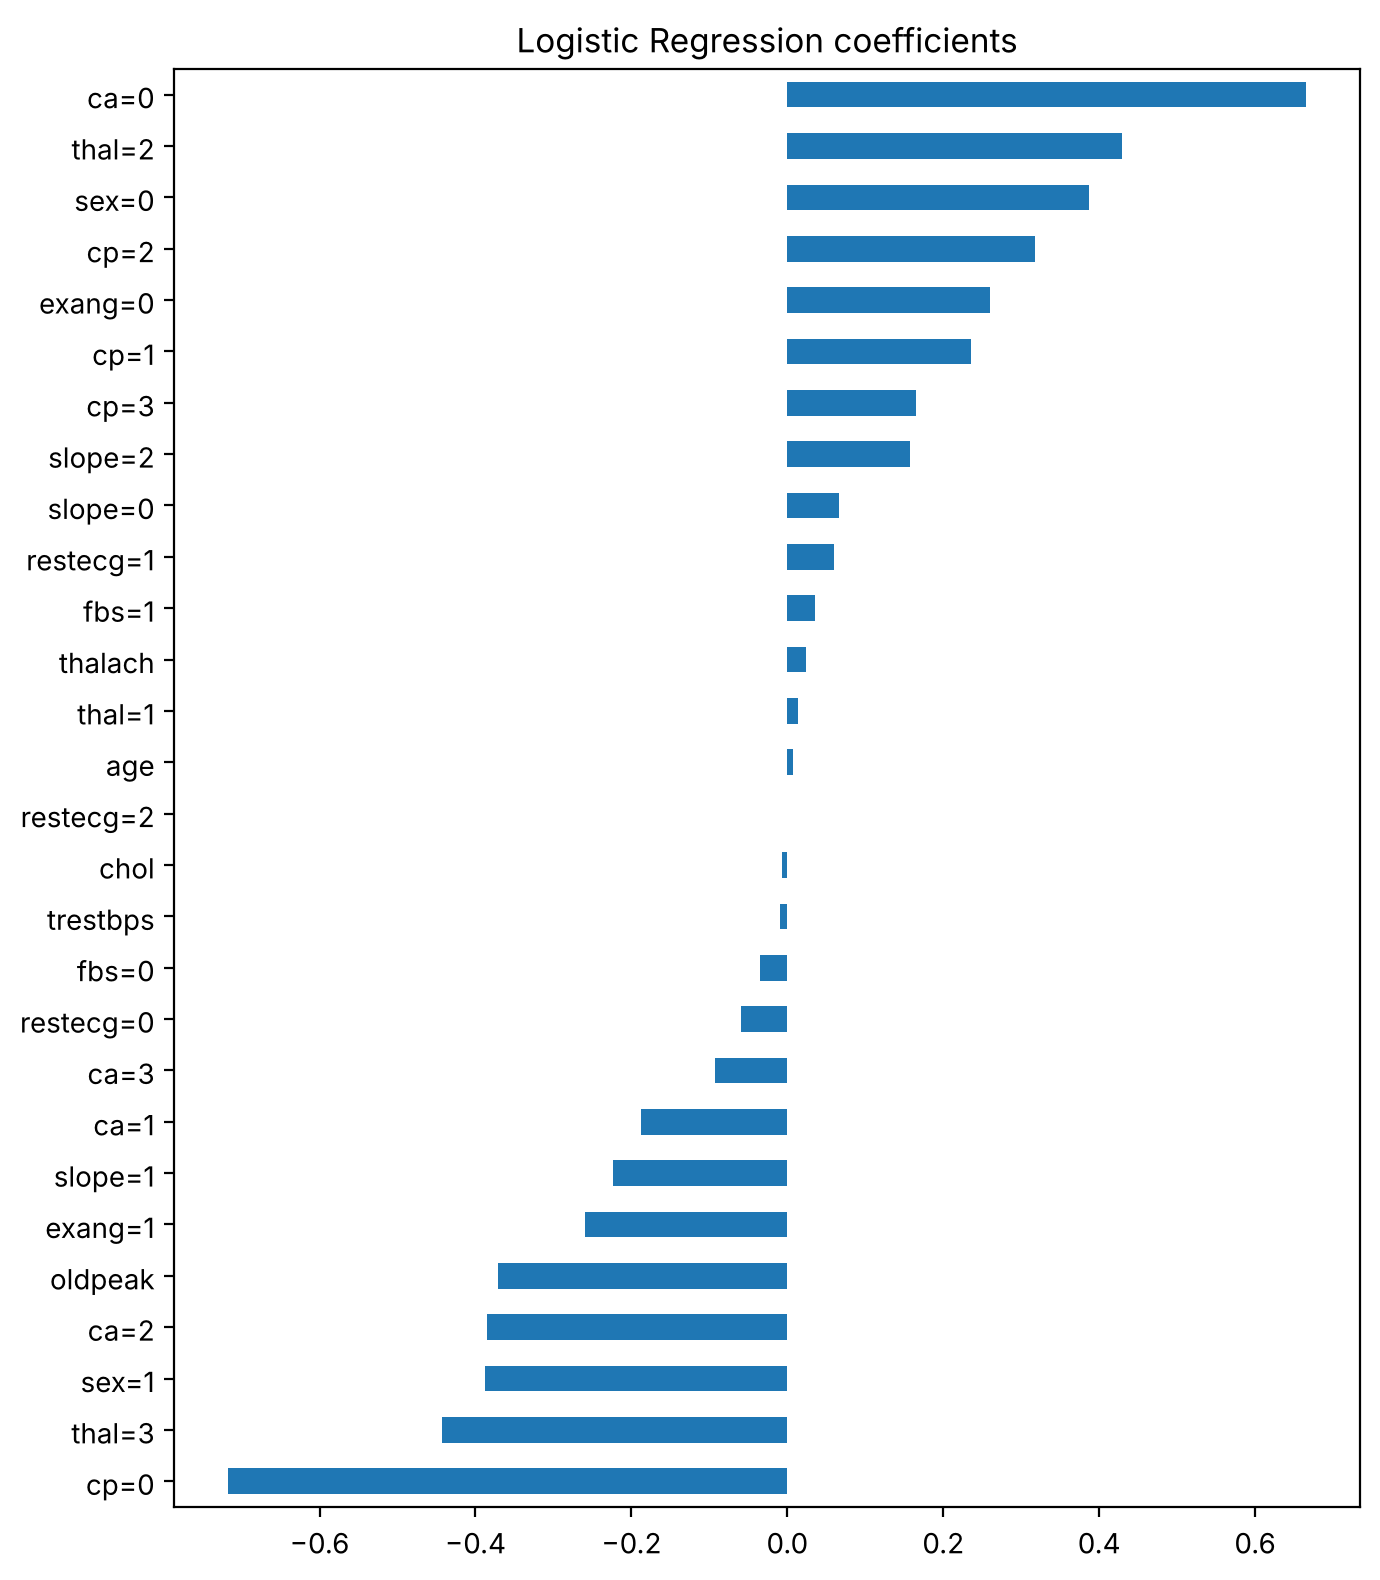

In [24]:
coefs = pd.Series(final_model.coef_[0], index=dv.get_feature_names_out())
coefs.sort_values().plot(kind='barh', figsize=(7, 8))
plt.title('Logistic Regression coefficients')
plt.tight_layout()
plt.show()

## Conclusion

* The final Logistic Regression model reaches a test AUC of 0.900 and a test accuracy of 0.836, close to its cross-validation AUC (0.916), so it generalises well to unseen patients.
* The training logic of this notebook is exported to `train.py`, and the model is served by `predict.py` (Flask).